# Set Up Libraries and Data

In [ ]:
# import packages
import scipy.io as sio  # for loading matlab data

import numpy as np      # for numerical libs

from matplotlib.ticker import FuncFormatter # for custom bar plot labels

import matplotlib.pyplot as plt  # for plotting

import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
from statsmodels.tsa import stattools
import pandas as pd


ModuleNotFoundError: No module named 'scipy'

In [ ]:
path = "data/MSFT_20141121.mat"
data = sio.loadmat(path)
# data = sio.loadmat('MSFT_20141121.mat')
# data = sio.loadmat('MSFT_20141103.mat')
# data = sio.loadmat('GOOG_20141103.mat')

LOB=data['LOB']

t = (np.array((LOB['EventTime'][0][0][:,0]))-3600000*9.5)*1e-3#time in seconds, measured from NASDAQ opening at 9:30am
bid = np.array(LOB['BuyPrice'][0][0]*1e-4)
bidvol = np.array(LOB['BuyVolume'][0][0]*1.0)
ask = np.array(LOB['SellPrice'][0][0]*1e-4)
askvol = np.array(LOB['SellVolume'][0][0]*1.0)
nMO = np.array(LOB['NumberMO'][0][0]*1.0)#total number of MOs submitted in the given 0.1 second interval
vMO = np.array(LOB['VolumeMO'][0][0]*1.0)#total volume of MOs submitted in the given 0.1 second interval
MO=np.array(LOB['MO'][0][0]*1.0)#information about market orders

best_bid = bid[:, 0].flatten()
best_ask = ask[:, 0].flatten()
vMO_buy = vMO[:, 0]
midprice = (bid[:, 0] + ask[:, 0]) / 2.0

dt = t[1]-t[0]
# print(dt)
# print(t[0:10])
# print(len(t))
# print(len(bid[:,0]))
# print(t[-1])
tcur = 10*60*40

# Name & Shape Check
field_names = LOB.dtype.names
#print("--- Internal Fields Inside 'LOB' ---")
#print(field_names)
#print("-" * 36)

for field in field_names:
    field_data = LOB[field][0, 0]
    print(f"Field: {field:<15} | Shape: {field_data.shape}")

NameError: name 'sio' is not defined

# Parameters and Estimation of q

In [ ]:
T = 600            # Termination time
k = 10            # Number of imbalance states
s = 0.01          # Bid-Ask spread

#Imbalance Grid from -1.0 to +1.0
edges = np.linspace(-1.0, 1.0, k + 1)
X = 0.5 * (edges[:-1] + edges[1:])
print(X)

#compute LO imbalance for each time stamp
rho = np.array((bidvol[:,0]-askvol[:,0])/(bidvol[:,0]+askvol[:,0]),ndmin=2).T
rho_flat = rho.flatten()

# Value matrix initialized to 0
v = np.zeros((T + 1, k))
# Policy matrix: 0 = CONTINUE, 1 = STOP
policy = np.zeros((T + 1, k), dtype=int)

[-0.9 -0.7 -0.5 -0.3 -0.1  0.1  0.3  0.5  0.7  0.9]


[0 0 0 ... 2 0 9]


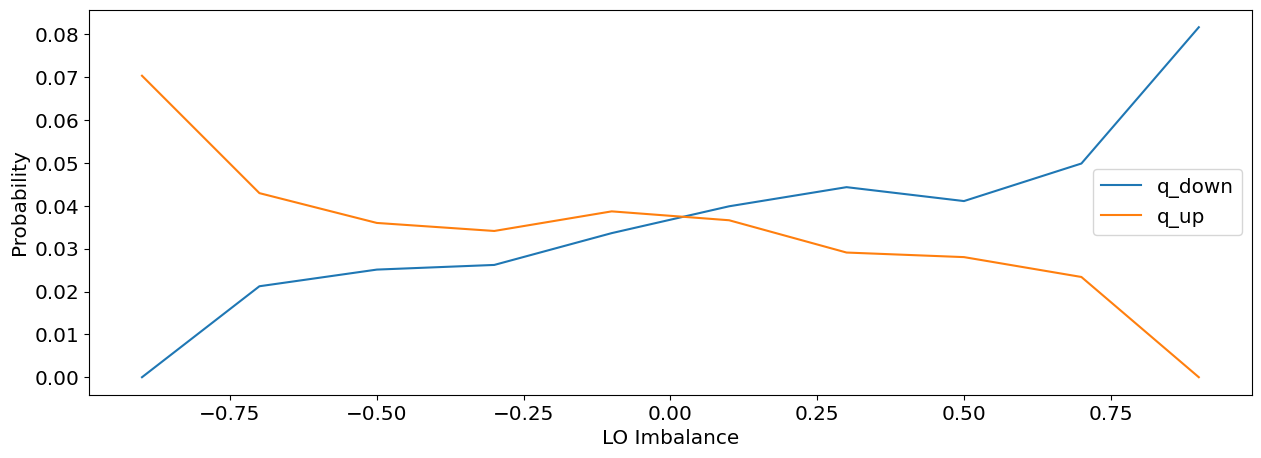

In [ ]:
# q_down = prob of imbalance moving down, q_up = prob of imbalance moving up
def estimate_q(idx_series, K):
    q_down = np.zeros(K)
    q_up = np.zeros(K)
    count = np.zeros(K, dtype=int)

    for i in range(K):
        mask = (idx_series[:-1] == i)
        n = mask.sum()
        count[i] = n
        if n == 0:
            continue
        nxt = idx_series[1:][mask]
        if i > 0:
            q_down[i] = np.mean(nxt < i)
        if i < K:
            q_up[i] = np.mean(nxt > i)
    return q_down, q_up, count

idx_series = np.array([np.argmin(np.abs(X - r)) for r in rho_flat])
print(idx_series)
q_down, q_up, q_count = estimate_q(idx_series, k)

# graph shows q_up and q_down w.r.t. index of imbalance levels
plt.plot(X, q_down, label='q_down')
plt.plot(X, q_up, label='q_up')
plt.xlabel("LO Imbalance")
plt.ylabel("Probability")
plt.legend()
plt.show()

# Estimate p and pi

p  (crash prob):  [0.02472839 0.0108448  0.00665808 0.00453415 0.00325606 0.00231444
 0.00197176 0.00145342 0.00165516 0.00290348]
pi (fill  prob):  [0.00689152 0.00565023 0.00621666 0.00637707 0.00767714 0.01052906
 0.01466993 0.01739416 0.02505565 0.04044854]
p + pi:           [0.03161991 0.01649503 0.01287475 0.01091122 0.01093321 0.0128435
 0.01664169 0.01884758 0.0267108  0.04335202]
Sample count:     [12334 21946 27185 34185 33476 30677 25358 21329 17521  9988]


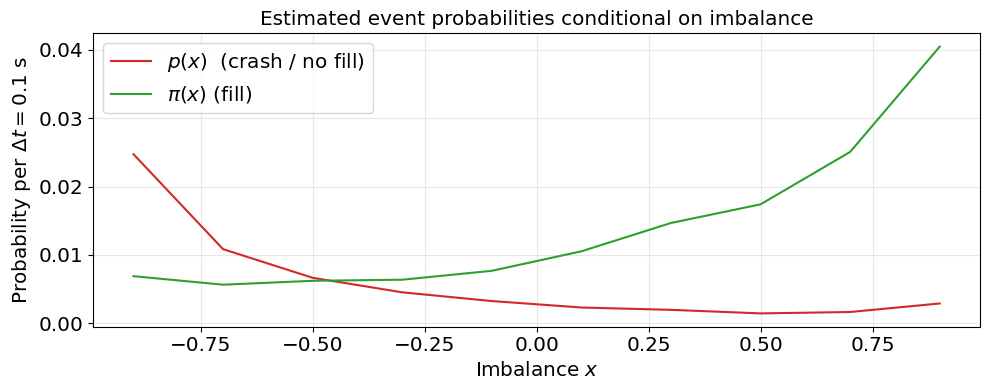

In [ ]:
# Estimate p (prob of price dropping) and pi (prob of LO being filled)
def estimate_probs(rho_flat, idx_series, K, best_bid, nMO, dt_sec=0.1):
    N = len(idx_series)

    buy_mo_event  = (nMO[1:, 0] > 0)                           # buy MO in next dt   SEE IF 1: MAKES MORE SENSE THAN :-1
    bid_drop_event = (best_bid[1:] < best_bid[:-1])             # bid fell next dt

    p_est  = np.zeros(K + 1)
    pi_est = np.zeros(K + 1)
    count  = np.zeros(K + 1, dtype=int)

    for i in range(K + 1):
        mask = (idx_series[:-1] == i)
        n    = mask.sum()
        count[i] = n
        if n == 0:
            continue
        e_mo   = buy_mo_event[mask]
        e_drop = bid_drop_event[mask]
        pi_est[i] = np.mean(e_mo)   # bMO arrives
        p_est[i]  = np.mean(e_drop & ~e_mo) # price goes down & no bMO

    # Enforce p + pi <= 1 everywhere (clamp numerical noise)
    excess = np.maximum(0, p_est + pi_est - 1.0)
    pi_est = np.maximum(0, pi_est - excess)

    return p_est, pi_est, count

p, pi, prob_count = estimate_probs(rho_flat, idx_series, k-1, best_bid, nMO)

assert np.all(p  >= 0) and np.all(p  <= 1), "p out of [0,1]"
assert np.all(pi >= 0) and np.all(pi <= 1), "pi out of [0,1]"
assert np.all(p + pi <= 1),                 "p + pi must be ≤ 1 everywhere"

print("p  (crash prob): ", p)
print("pi (fill  prob): ", pi)
print("p + pi:          ", p + pi)
print("Sample count:    ", prob_count)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(X, p, label=r'$p(x)$  (crash / no fill)',   color='C3')
ax.plot(X, pi, label=r'$\pi(x)$ (fill)',    color='C2')
ax.set_xlabel(r'Imbalance $x$')
ax.set_ylabel('Probability per $\\Delta t = 0.1$ s')
ax.set_title('Estimated event probabilities conditional on imbalance')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate and Plot Stopping Boundaries

In [ ]:
v[T, :] = -s/2
policy[T, :] = 1

for t in range(T - 1, -1, -1):
    time_remaining = (T - t) / T
    pi_t = pi
    p_t  = p

    assert np.all(p_t  >= 0) and np.all(p_t  <= 1), "crash prob out of [0,1]"
    assert np.all(pi_t >= 0) and np.all(pi_t <= 1), "fill  prob out of [0,1]"
    assert np.all(p_t + pi_t <= 1), "p + pi must be ≤ 1 everywhere"

    for i in range(k):
        if i == 0:
            ev_next = (1 - q_up[i]) * v[t + 1, i] + q_up[i] * v[t + 1, i + 1]
        elif i == k - 1:
            ev_next = (1 - q_down[i]) * v[t + 1, i] + q_down[i] * v[t + 1, i - 1]
        else:
            ev_next = q_up[i] * v[t + 1, i + 1] + (1 - q_down[i] - q_up[i]) * v[t + 1, i] + q_down[i] * v[t + 1, i - 1]

        continuation = -(3.0 * s / 2.0) * p_t[i] + (s / 2.0) * pi_t[i] + (1.0 - p_t[i] - pi_t[i]) * ev_next
        immediate_stop = -s / 2.0

        if continuation > immediate_stop:
            v[t, i] = continuation
            policy[t, i] = 0
        else:
            v[t, i] = immediate_stop
            policy[t, i] = 1

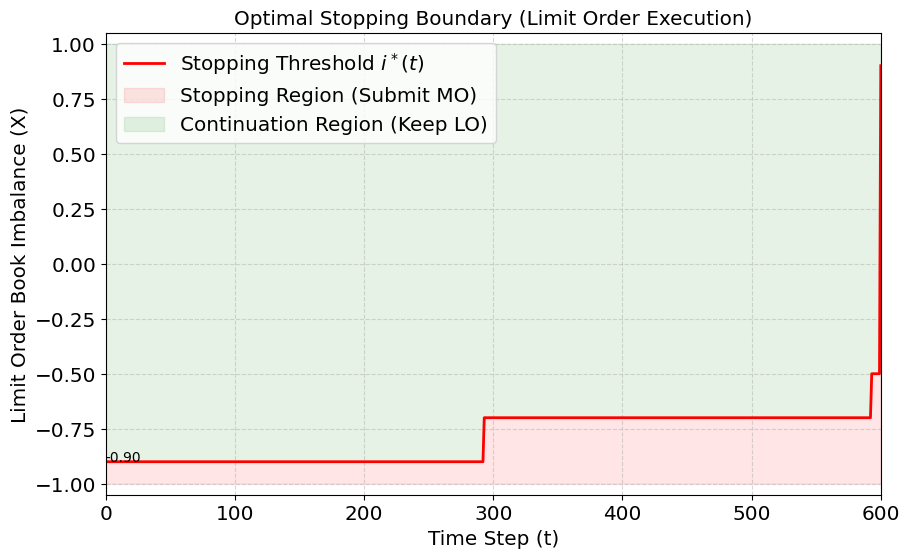

In [ ]:
stopping_boundary = []
time_axis = range(T+1)

for t in time_axis:
    # Find all states at time t where policy == 1 (STOP)
    stop_indices = np.where(policy[t, :] == 1)[0]

    if len(stop_indices) > 0:
        max_stop_idx = np.max(stop_indices)
        stopping_boundary.append(X[max_stop_idx])
    else:
        stopping_boundary.append(-1.1)

plt.figure(figsize=(10, 6))
plt.plot(time_axis, stopping_boundary, label="Stopping Threshold $i^*(t)$", color='red', lw=2)

plt.annotate(f"{stopping_boundary[0]:.2f}",
             xy=(0, stopping_boundary[0]))

plt.fill_between(time_axis, -1.0, stopping_boundary, color='red', alpha=0.1, label="Stopping Region (Submit MO)")
plt.fill_between(time_axis, stopping_boundary, 1.0, color='green', alpha=0.1, label="Continuation Region (Keep LO)")

plt.xlim(0, T)
plt.ylim(-1.05, 1.05)
plt.title("Optimal Stopping Boundary (Limit Order Execution)")
plt.xlabel("Time Step (t)")
plt.ylabel("Limit Order Book Imbalance (X)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.show()

# Sample Size Testing

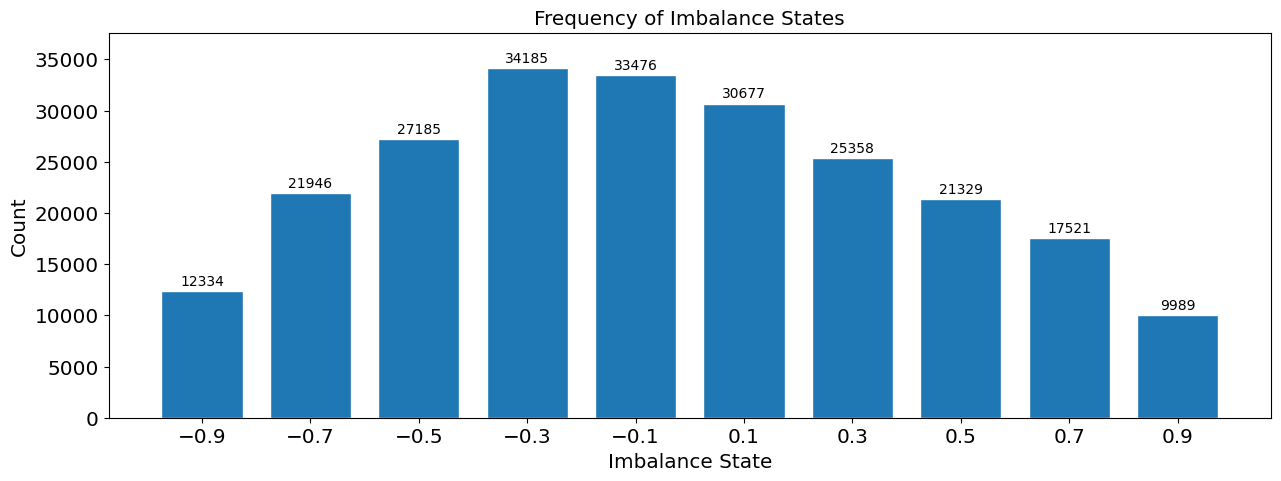

In [ ]:
counts = [0] * 10

for item in idx_series:
    counts[item] += 1

states = [-0.9, -0.7, -0.5, -0.3, -0.1,
           0.1,  0.3,  0.5,  0.7,  0.9]

fig, ax = plt.subplots()

bars = ax.bar(states, counts, width=0.15, edgecolor='white')

ax.bar_label(bars, padding=2)

ax.set_xlabel("Imbalance State")
ax.set_ylabel("Count")
ax.set_xticks(states)
plt.title("Frequency of Imbalance States")

plt.margins(y=0.1)
plt.show()

In [ ]:
def calculate_sufficient_sample_size(probability, error):
    variance = probability * (1 - probability)
    numerator = 1.96**2 * variance
    result = numerator / (error**2)
    return result

state = -0.9
error = 0.005
print(f"TESTING 95% CONFIDENCE WITH ERROR = {error}: \n \n")

for i in range(k):
    print(f"Sample Size required for q_up (state {state}):")
    up_result = calculate_sufficient_sample_size(q_up[i], error)
    print(np.ceil(up_result).astype(int))
    print(f"Sample Size required for q_down (state {state}):")
    down_result = calculate_sufficient_sample_size(q_down[i], error)
    print(np.ceil(down_result).astype(int))
    print()
    state = np.round(state + 0.2, decimals=1)

#for down_prob in q_down:

TESTING 95% CONFIDENCE WITH ERROR = 0.005: 
 

Sample Size required for q_up (state -0.9):
10054
Sample Size required for q_down (state -0.9):
0

Sample Size required for q_up (state -0.7):
6320
Sample Size required for q_down (state -0.7):
3194

Sample Size required for q_up (state -0.5):
5335
Sample Size required for q_down (state -0.5):
3764

Sample Size required for q_up (state -0.3):
5067
Sample Size required for q_down (state -0.3):
3923

Sample Size required for q_up (state -0.1):
5719
Sample Size required for q_down (state -0.1):
4995

Sample Size required for q_up (state 0.1):
5424
Sample Size required for q_down (state 0.1):
5887

Sample Size required for q_up (state 0.3):
4342
Sample Size required for q_down (state 0.3):
6515

Sample Size required for q_up (state 0.5):
4188
Sample Size required for q_down (state 0.5):
6059

Sample Size required for q_up (state 0.7):
3512
Sample Size required for q_down (state 0.7):
7283

Sample Size required for q_up (state 0.9):
0
Sample Si